# Học phân loại với dữ liệu thu nhập Adult Census

Notebook này dạy từng bước: xử lý nhiều cột categorical bằng one-hot encoding, logistic regression, cây quyết định, random forest, xử lý lớp mất cân bằng và kiểm tra mô hình có công bằng giữa các nhóm không.

Dữ liệu: 48.842 người trưởng thành trong điều tra dân số Mỹ năm 1994. Biến mục tiêu income cho biết người đó có thu nhập trên 50.000 USD/năm (>50K) hay không (<=50K). Có 6 cột số và 8 cột chữ (nghề nghiệp, học vấn, tình trạng hôn nhân...). Nguồn: Adult dataset, UCI, bản gộp train và test (bản sao trên GitHub của jbrownlee/Datasets).

Chuẩn bị:
1. Đặt file data6.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib seaborn scikit-learn

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào DataFrame và kiểm tra kích thước.

Kiến thức: pd.read_csv đọc file thành bảng. df.shape trả về (số dòng, số cột).

Kết quả mong đợi: (48842, 15).

In [2]:
df = pd.read_csv('data6.csv')
print(df.shape)
print(df.head())

(48842, 15)
   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country income  
0          2174             0              40  United-States  <=50K  
1             0             0 

## Bước 2: Tìm giá trị thiếu bị ẩn

Mục tiêu: phát hiện ô trống được ghi bằng dấu "?" thay vì để trống.

Kiến thức: isna() chỉ đếm ô NaN. Nhiều bộ dữ liệu ghi giá trị thiếu bằng "?", "unknown" hoặc -1, nên isna() báo 0. Cần đổi các ký hiệu này thành np.nan bằng replace.

Kết quả mong đợi: isna() báo 0 ô trống. Có '?' ở 3 cột: workclass 2799, occupation 2809, native_country 857. Khoảng 7,4% số dòng có ít nhất một ô trống.

Câu hỏi: bạn nên xóa các dòng có "?" hay điền giá trị khác vào? Xóa thì mất bao nhiêu phần trăm dữ liệu?

In [3]:
print('NaN ban đầu:', df.isna().sum().sum())
q = (df == '?').sum()
print(q[q > 0])
df = df.replace('?', np.nan)
na = df.isna().sum()
print(na[na > 0])
print('Tỷ lệ dòng có ô trống:', round(df.isna().any(axis=1).mean(), 3))

NaN ban đầu: 0
workclass         2799
occupation        2809
native_country     857
dtype: int64
workclass         2799
occupation        2809
native_country     857
dtype: int64
Tỷ lệ dòng có ô trống: 0.074


## Bước 3: Biến mục tiêu

Mục tiêu: tạo y dạng 0/1 và xem tỷ lệ người thu nhập cao.

Kiến thức: lớp >50K chiếm khoảng một phần tư, nên dữ liệu hơi mất cân bằng. Accuracy của mô hình luôn đoán <=50K đã là khoảng 0,76.

Kết quả mong đợi: <=50K có 37155 người, >50K có 11687 người. Tỷ lệ >50K khoảng 0,239.

In [4]:
y = (df['income'] == '>50K').astype(int)
print(df['income'].value_counts())
print('Tỷ lệ >50K:', round(y.mean(), 3))

income
<=50K    37155
>50K     11687
Name: count, dtype: int64
Tỷ lệ >50K: 0.239


## Bước 4: Tỷ lệ thu nhập cao theo nhóm

Mục tiêu: xem học vấn, giới tính và tình trạng hôn nhân liên quan đến thu nhập thế nào.

Kiến thức: groupby(cột)[y].mean() với y là 0/1 cho ra tỷ lệ >50K trong mỗi nhóm. Đây là cách nhanh nhất để khám phá cột categorical.

Kết quả mong đợi: nữ khoảng 0,109, nam khoảng 0,304. Người đã kết hôn (Married-civ-spouse) có tỷ lệ cao nhất, khoảng 0,446. Người chưa kết hôn (Never-married) chỉ khoảng 0,045. Tỷ lệ >50K tăng rõ khi education_num tăng.

Câu hỏi: tỷ lệ >50K của nam cao gần gấp 3 lần nữ. Nếu mô hình học theo dữ liệu này, có rủi ro gì khi dùng để duyệt khoản vay?

sex
Female    0.109
Male      0.304
Name: y, dtype: float64
marital_status
Married-civ-spouse       0.446
Married-AF-spouse        0.378
Divorced                 0.101
Married-spouse-absent    0.092
Widowed                  0.084
Separated                0.065
Never-married            0.045
Name: y, dtype: float64


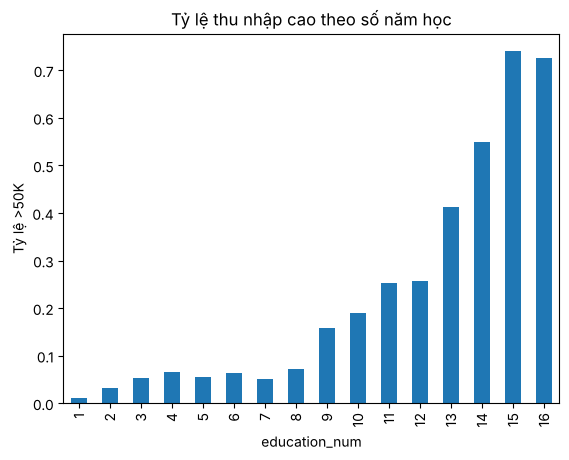

In [5]:
df['y'] = y
print(df.groupby('sex')['y'].mean().round(3))
print(df.groupby('marital_status')['y'].mean().sort_values(ascending=False).round(3))
df.groupby('education_num')['y'].mean().plot(kind='bar')
plt.ylabel('Tỷ lệ >50K')
plt.title('Tỷ lệ thu nhập cao theo số năm học')
plt.show()

## Bước 5: Chọn feature

Mục tiêu: bỏ các cột không nên dùng và chia nhóm cột số, cột chữ.

Kiến thức: fnlwgt là trọng số mẫu của cuộc điều tra, cho biết một dòng đại diện cho bao nhiêu người, không phải đặc điểm của người đó. education và education_num mang cùng thông tin (education_num là dạng số của education), giữ cả hai là thừa.

Kết quả mong đợi: 5 cột số (age, education_num, capital_gain, capital_loss, hours_per_week) và 7 cột chữ. native_country có nhiều giá trị nhất (41), occupation có 14.

In [6]:
X = df.drop(columns=['income', 'y', 'fnlwgt', 'education'])
num_cols = X.select_dtypes('number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print('num_cols:', num_cols)
print('cat_cols:', cat_cols)
print(X[cat_cols].nunique())

num_cols: ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
cat_cols: ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
workclass          8
marital_status     7
occupation        14
relationship       6
race               5
sex                2
native_country    41
dtype: int64


## Bước 6: Chia train/test

Mục tiêu: giữ 20% làm tập test, giữ nguyên tỷ lệ >50K.

Kiến thức: stratify=y giữ tỷ lệ lớp. random_state=42 giúp kết quả lặp lại được.

Kết quả mong đợi: X_train có 39073 dòng, X_test có 9769 dòng. Tỷ lệ >50K ở hai tập đều khoảng 0,239.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

(39073, 12) (9769, 12)
0.239 0.239


## Bước 7: Pipeline với one-hot encoding

Mục tiêu: biến 8 cột chữ thành các cột 0/1 và chuẩn hóa cột số trong một pipeline.

Kiến thức: OneHotEncoder tạo một cột cho mỗi giá trị. Ví dụ cột sex tạo ra sex_Female và sex_Male. Ô trống ở cột chữ được điền bằng giá trị xuất hiện nhiều nhất (most_frequent). handle_unknown="ignore" tránh lỗi khi tập test có giá trị hiếm chưa xuất hiện trong tập train.

Kết quả mong đợi: sau khi biến đổi có 88 cột: 5 cột số và 83 cột one-hot.

Câu hỏi: vì sao không thể đổi occupation thành số 0, 1, 2, ... như cách làm với cột hai giá trị ở Data1?

In [8]:
cat_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore'))])
prep = ColumnTransformer([('num', StandardScaler(), num_cols), ('cat', cat_pipe, cat_cols)])
Xt = prep.fit_transform(X_train)
print(Xt.shape)

(39073, 88)


## Bước 8: Logistic regression

Mục tiêu: huấn luyện mô hình đầu tiên và so với baseline.

Kiến thức: hàm evaluate dưới đây in 5 chỉ số cùng lúc. Bạn sẽ dùng lại nó cho mọi mô hình phía sau.

Kết quả mong đợi: baseline: accuracy khoảng 0,761, recall bằng 0, AUC 0,5. Logistic: accuracy khoảng 0,851, precision khoảng 0,729, recall khoảng 0,600, F1 khoảng 0,658, AUC khoảng 0,904.

In [9]:
def evaluate(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    res = {'Mô hình': name, 'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred, zero_division=0),
           'recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred), 'AUC': roc_auc_score(y_test, proba)}
    print(' | '.join(f'{k}: {v:.3f}' if isinstance(v, float) else v for k, v in res.items()))
    return res

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
evaluate(dummy, 'Baseline')
lr = Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=2000))])
lr.fit(X_train, y_train)
res_lr = evaluate(lr, 'Logistic')

Baseline | accuracy: 0.761 | precision: 0.000 | recall: 0.000 | F1: 0.000 | AUC: 0.500


Logistic | accuracy: 0.851 | precision: 0.729 | recall: 0.600 | F1: 0.658 | AUC: 0.904


## Bước 9: Đọc odds ratio

Mục tiêu: tìm các đặc điểm làm tăng hoặc giảm mạnh khả năng thu nhập cao.

Kiến thức: odds ratio = exp(hệ số). Với cột one-hot, OR so sánh nhóm đó với mức chung. Với cột số đã chuẩn hóa, OR là thay đổi của odds khi cột tăng một độ lệch chuẩn. OR lớn hơn 1 làm tăng khả năng >50K.

Kết quả mong đợi: capital_gain có OR lớn nhất, khoảng 10,0. Married-civ-spouse khoảng 4,12, education_num khoảng 2,20. Ở phía nhỏ: Priv-house-serv khoảng 0,22, Never-married khoảng 0,34, sex_Female khoảng 0,38. Một số nước như France hay Cambodia có OR lớn chỉ vì có rất ít mẫu.

In [10]:
names = lr.named_steps['prep'].get_feature_names_out()
odds = pd.Series(np.exp(lr.named_steps['model'].coef_[0]), index=names).sort_values()
print('OR lớn nhất:')
print(odds.tail(8)[::-1].round(2))
print('OR nhỏ nhất:')
print(odds.head(8).round(2))

OR lớn nhất:
num__capital_gain                         10.00
cat__marital_status_Married-civ-spouse     4.12
cat__marital_status_Married-AF-spouse      3.03
cat__native_country_France                 2.63
cat__relationship_Wife                     2.46
cat__native_country_Cambodia               2.29
num__education_num                         2.20
cat__occupation_Exec-managerial            2.17
dtype: float64
OR nhỏ nhất:
cat__occupation_Priv-house-serv      0.22
cat__native_country_South            0.23
cat__native_country_Columbia         0.33
cat__marital_status_Never-married    0.34
cat__relationship_Own-child          0.36
cat__sex_Female                      0.38
cat__occupation_Farming-fishing      0.40
cat__relationship_Other-relative     0.43
dtype: float64


## Bước 10: Xử lý mất cân bằng bằng class_weight

Mục tiêu: tăng recall cho lớp >50K.

Kiến thức: class_weight="balanced" cho mỗi mẫu của lớp hiếm trọng số lớn hơn, tỷ lệ nghịch với số mẫu của lớp. Mô hình sẽ bị phạt nặng hơn khi bỏ sót lớp >50K. Kết quả thường là recall tăng, precision giảm.

Kết quả mong đợi: recall tăng từ khoảng 0,600 lên khoảng 0,837, precision giảm từ khoảng 0,729 xuống khoảng 0,565, accuracy giảm xuống khoảng 0,807. AUC giữ nguyên khoảng 0,904, vì class_weight chủ yếu dời ngưỡng quyết định.

Câu hỏi: nếu mô hình dùng để gửi quảng cáo sản phẩm cao cấp, bạn ưu tiên precision hay recall?

In [11]:
lr_bal = Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))])
lr_bal.fit(X_train, y_train)
res_lr_bal = evaluate(lr_bal, 'Logistic balanced')

Logistic balanced | accuracy: 0.807 | precision: 0.565 | recall: 0.837 | F1: 0.675 | AUC: 0.904


## Bước 11: Cây quyết định và độ sâu

Mục tiêu: tìm độ sâu hợp lý cho cây quyết định.

Kiến thức: cây không cần chuẩn hóa, nhưng pipeline prep vẫn dùng được vì chuẩn hóa không đổi thứ tự giá trị. Cây sâu học thuộc tập train: accuracy train tăng nhưng test giảm.

Kết quả mong đợi: accuracy test cao nhất ở độ sâu 10 (khoảng 0,862), AUC test cao nhất ở độ sâu 8 (khoảng 0,907). Cây không giới hạn có accuracy train khoảng 0,974 nhưng test chỉ khoảng 0,824 và AUC khoảng 0,775.

In [12]:
for depth in [2, 4, 6, 8, 10, 15, None]:
    tree = Pipeline([('prep', prep), ('model', DecisionTreeClassifier(max_depth=depth, random_state=42))])
    tree.fit(X_train, y_train)
    print(f'depth={str(depth):>4} | train acc={tree.score(X_train, y_train):.3f} | test acc={tree.score(X_test, y_test):.3f}'
          f' | test AUC={roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]):.3f}')

depth=   2 | train acc=0.829 | test acc=0.830 | test AUC=0.839


depth=   4 | train acc=0.845 | test acc=0.846 | test AUC=0.872


depth=   6 | train acc=0.857 | test acc=0.858 | test AUC=0.897


depth=   8 | train acc=0.861 | test acc=0.858 | test AUC=0.907


depth=  10 | train acc=0.869 | test acc=0.862 | test AUC=0.901


depth=  15 | train acc=0.889 | test acc=0.853 | test AUC=0.872


depth=None | train acc=0.974 | test acc=0.824 | test AUC=0.775


## Bước 12: Đọc một cây nhỏ

Mục tiêu: vẽ cây độ sâu 3 và đọc quy tắc của nó.

Kiến thức: plot_tree vẽ cây. Mỗi nút ghi điều kiện chia, gini, số mẫu (samples) và số mẫu mỗi lớp (value). Cột one-hot có dạng cat__marital_status_Married-civ-spouse <= 0.5, nghĩa là "không phải Married-civ-spouse".

Kết quả mong đợi: nút gốc chia theo cat__marital_status_Married-civ-spouse <= 0.5. Nhánh chưa kết hôn chia tiếp theo capital_gain, nhánh đã kết hôn chia theo education_num. Lưu ý các ngưỡng của cột số ở đơn vị đã chuẩn hóa, không phải đơn vị gốc.

Câu hỏi: tại sao capital_gain xuất hiện ở tầng thứ hai dù chỉ khoảng 8% người có capital_gain lớn hơn 0?

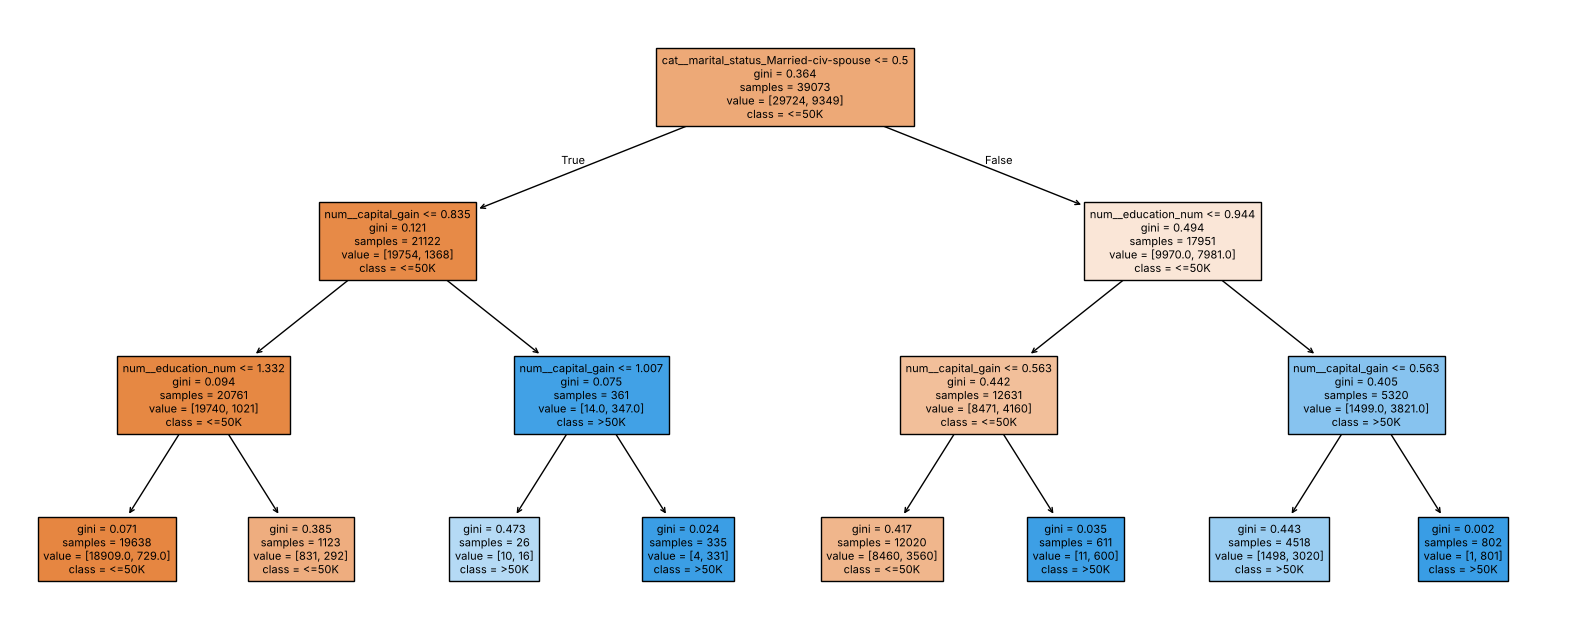

In [13]:
tree3 = Pipeline([('prep', prep), ('model', DecisionTreeClassifier(max_depth=3, random_state=42))])
tree3.fit(X_train, y_train)
plt.figure(figsize=(20, 8))
plot_tree(tree3.named_steps['model'], feature_names=tree3.named_steps['prep'].get_feature_names_out(),
          class_names=['<=50K', '>50K'], filled=True, fontsize=8)
plt.show()

## Bước 13: Random forest

Mục tiêu: huấn luyện random forest và so sánh với cây đơn.

Kiến thức: min_samples_leaf=5 buộc mỗi lá có ít nhất 5 mẫu, giúp giảm overfitting. n_jobs=-1 dùng mọi nhân CPU. Bước này mất khoảng 20 giây.

Kết quả mong đợi: cây độ sâu 10: accuracy khoảng 0,862, AUC khoảng 0,901. Random forest: accuracy khoảng 0,868, precision khoảng 0,799, recall khoảng 0,602, AUC khoảng 0,919.

In [14]:
tree10 = Pipeline([('prep', prep), ('model', DecisionTreeClassifier(max_depth=10, random_state=42))]).fit(X_train, y_train)
res_tree = evaluate(tree10, 'Tree depth 10')
rf = Pipeline([('prep', prep), ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                                n_jobs=-1, random_state=42))])
rf.fit(X_train, y_train)
res_rf = evaluate(rf, 'Random forest')

Tree depth 10 | accuracy: 0.862 | precision: 0.792 | recall: 0.577 | F1: 0.667 | AUC: 0.901


Random forest | accuracy: 0.868 | precision: 0.799 | recall: 0.602 | F1: 0.687 | AUC: 0.919


## Bước 14: Permutation importance trên cột gốc

Mục tiêu: biết cột gốc nào (trước one-hot) quan trọng nhất với random forest.

Kiến thức: gọi permutation_importance trên cả pipeline và X_test gốc: mỗi lần xáo trộn một cột như occupation, rồi xem AUC giảm bao nhiêu. Cách này cho một con số cho mỗi cột gốc, dễ đọc hơn importance của hàng chục cột one-hot. Dùng 3000 dòng đầu của X_test để chạy nhanh hơn.

Kết quả mong đợi: capital_gain (khoảng 0,042) và marital_status (khoảng 0,041) đứng đầu, sau đó là education_num (khoảng 0,028). race và native_country gần như bằng 0.

In [15]:
perm = permutation_importance(rf, X_test[:3000], y_test[:3000], n_repeats=5, random_state=42,
                              scoring='roc_auc', n_jobs=-1)
print(pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).round(4))

capital_gain      0.0424
marital_status    0.0408
education_num     0.0276
age               0.0153
relationship      0.0146
occupation        0.0138
hours_per_week    0.0090
capital_loss      0.0075
workclass         0.0031
sex               0.0021
race              0.0005
native_country   -0.0001
dtype: float64


## Bước 15: Kiểm tra công bằng theo giới tính

Mục tiêu: xem mô hình đối xử với nam và nữ có khác nhau không.

Kiến thức: so sánh theo nhóm: tỷ lệ được dự đoán >50K, recall (trong những người thật sự >50K, mô hình nhận ra bao nhiêu) và precision. Mô hình có thể có accuracy chung cao nhưng recall thấp hơn ở một nhóm. Đây là một phần của đạo đức dữ liệu (data ethics).

Kết quả mong đợi: nam: tỷ lệ thật >50K khoảng 0,304, tỷ lệ dự đoán khoảng 0,236, recall khoảng 0,620. Nữ: tỷ lệ thật khoảng 0,112, tỷ lệ dự đoán khoảng 0,071, recall chỉ khoảng 0,504. Precision của hai nhóm gần bằng nhau (khoảng 0,80).

Câu hỏi: cột sex có trong feature. Nếu bỏ cột này đi, mô hình có hết thiên lệch không? Gợi ý: relationship có giá trị Husband và Wife.

In [16]:
pred_rf = rf.predict(X_test)
rows = []
for g in ['Male', 'Female']:
    m = (X_test['sex'] == g).values
    rows.append({'sex': g, 'n': m.sum(), 'tỷ lệ thật >50K': y_test[m].mean(), 'tỷ lệ dự đoán >50K': pred_rf[m].mean(),
                 'recall': recall_score(y_test[m], pred_rf[m]), 'precision': precision_score(y_test[m], pred_rf[m])})
print(pd.DataFrame(rows).round(3).to_string())

      sex     n  tỷ lệ thật >50K  tỷ lệ dự đoán >50K  recall  precision
0    Male  6480            0.304               0.236   0.620      0.799
1  Female  3289            0.112               0.071   0.504      0.797


## Bước 16: Bảng so sánh các mô hình

Mục tiêu: ghép kết quả của mọi mô hình vào một bảng.

Kiến thức: các dict kết quả từ hàm evaluate ghép được thành DataFrame.

Kết quả mong đợi: random forest có accuracy (khoảng 0,868), F1 (khoảng 0,687) và AUC (khoảng 0,919) cao nhất. Logistic balanced có recall cao nhất (khoảng 0,837) nhưng precision thấp nhất (khoảng 0,565).

Câu hỏi: random forest tốt hơn logistic bao nhiêu điểm AUC? Mức cải thiện đó có đáng với việc mô hình khó giải thích hơn không?

In [17]:
print(pd.DataFrame([res_lr, res_lr_bal, res_tree, res_rf]).round(3).to_string())

             Mô hình  accuracy  precision  recall     F1    AUC
0           Logistic     0.851      0.729   0.600  0.658  0.904
1  Logistic balanced     0.807      0.565   0.837  0.675  0.904
2      Tree depth 10     0.862      0.792   0.577  0.667  0.901
3      Random forest     0.868      0.799   0.602  0.687  0.919


## Bước 17: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Bỏ cả sex và relationship khỏi feature, huấn luyện lại random forest rồi chạy lại bước 15. Khoảng cách recall giữa nam và nữ thay đổi thế nào?
2. Thử RandomForestClassifier(class_weight='balanced'). So sánh precision và recall với res_rf.
3. Gộp các nước trong native_country thành 'United-States' và 'Other' rồi chạy lại logistic. Số cột sau one-hot giảm bao nhiêu? AUC có đổi không?
4. Viết ba câu tiếng Anh về kết quả bước 15 cho phần "Ethical considerations" của một báo cáo. Ví dụ: "The model predicted high income for ...% of men but only ...% of women."
